In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df=pd.read_csv('/content/PhiUSIIL_Phishing_URL_Dataset - PhiUSIIL_Phishing_URL_Dataset (1).csv')

print(df.head())
print("Dataset shape:",df.shape)
print(df.columns.tolist())

     FILENAME                                 URL  URLLength  \
0  521848.txt    https://www.southbankmosaics.com         31   
1   31372.txt            https://www.uni-mainz.de         23   
2  597387.txt      https://www.voicefmradio.co.uk         29   
3  554095.txt         https://www.sfnmjournal.com         26   
4  151578.txt  https://www.rewildingargentina.org         33   

                       Domain  DomainLength  IsDomainIP  TLD  \
0    www.southbankmosaics.com            24           0  com   
1            www.uni-mainz.de            16           0   de   
2      www.voicefmradio.co.uk            22           0   uk   
3         www.sfnmjournal.com            19           0  com   
4  www.rewildingargentina.org            26           0  org   

   URLSimilarityIndex  CharContinuationRate  TLDLegitimateProb  ...  Pay  \
0               100.0              1.000000           0.522907  ...    0   
1               100.0              0.666667           0.032650  ...    0   
2 

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVR
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    RocCurveDisplay
)

In [29]:
df.shape

(235795, 56)

In [30]:
df.isnull().sum()

,0
FILENAME,0
URL,0
URLLength,0
Domain,0
DomainLength,0
IsDomainIP,0
TLD,0
URLSimilarityIndex,0
CharContinuationRate,0
TLDLegitimateProb,0


In [31]:
df.value_counts()

,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,count
FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label,
oph15000.txt,https://intiwin.sa.com/service2/mon/tain/safe/mountain1.html,60,intiwin.sa.com,14,0,com,23.481634,0.800000,0.522907,0.059277,3,1,0,0,0.0,42,0.700,2,0.033,0,0,0,8,0.133,1,665,309601,1,intiwinsaservice2montainsafemountain1html,0.0,0.0,0,0,1,0,0,0,0,2,0,1,1,0,1,1,1,1,1,4,2,2,3,0,3,0,1
100000.txt,https://www.thesweet.com,23,www.thesweet.com,16,0,com,100.000000,1.000000,0.522907,0.064428,3,1,0,0,0.0,10,0.435,0,0.000,0,0,0,1,0.043,1,2532,656,1,thesweet,100.0,100.0,1,1,1,0,0,1,0,0,0,1,1,0,0,0,0,0,1,42,4,8,6,4,42,1,1
100011.txt,https://www.ricethresher.org,27,www.ricethresher.org,20,0,org,100.000000,1.000000,0.079963,0.065276,3,1,0,0,0.0,14,0.519,0,0.000,0,0,0,1,0.037,1,1089,482,1,ricethresher,100.0,100.0,1,0,1,0,0,1,0,2,0,1,0,1,0,0,1,0,1,29,6,12,129,0,157,1,1
oph14971.txt,http://ixgieriaiy.duckdns.org/,30,ixgieriaiy.duckdns.org,22,0,org,59.703844,0.611111,0.079963,0.050933,3,1,0,0,0.0,20,0.667,0,0.000,0,0,0,3,0.100,0,9,50,1,ixgieriaiyduckdns,0.0,0.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
oph14969.txt,http://techno2.nstru.ac.th/techno2022/img/banner/msmd/information.php?access.x71963332361&&data.x=en_86dc6520cdcf2337f0c26c795,126,techno2.nstru.ac.th,19,0,th,11.079961,0.500000,0.000510,0.039941,2,2,0,0,0.0,71,0.563,32,0.254,1,1,0,14,0.127,0,752,7901,1,techno2nstruactechno2022imgbannermsmdinformationphp?accessx71963332361&&datax=en_86dc6520cdcf2337f0c26c795,0.0,0.0,1,1,0,0,0,0,0,0,0,0,1,1,1,0,0,1,1,0,0,3,0,0,1,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
100045.txt,https://www.nature-one.de,24,www.nature-one.de,17,0,de,100.000000,0.700000,0.032650,0.065731,2,1,0,0,0.0,10,0.417,0,0.000,0,0,0,2,0.083,1,885,6851,1,nature-one,100.0,100.0,1,1,1,0,0,1,0,3,0,1,0,1,0,0,0,0,0,54,3,12,3,0,28,1,1
100041.txt,https://www.imcce.fr,19,www.imcce.fr,12,0,fr,100.000000,1.000000,0.014148,0.062491,2,1,0,0,0.0,6,0.316,0,0.000,0,0,0,1,0.053,1,496,335,1,imcce,100.0,100.0,0,0,1,0,0,1,0,0,0,0,1,1,0,0,0,0,0,5,2,3,54,5,17,1,1
100031.txt,https://www.monkees.com,22,www.monkees.com,15,0,com,100.000000,1.000000,0.522907,0.071952,3,1,0,0,0.0,9,0.409,0,0.000,0,0,0,1,0.045,1,7098,907,1,monkees,100.0,100.0,1,1,1,0,0,1,0,8,0,1,1,1,0,1,1,0,1,19,8,32,47,1,20,1,1


In [32]:
df=df.dropna(subset=["label"]).copy()

In [33]:
y=(df["label"]==0).astype(int)

In [34]:
x=df.drop(
    columns=["label","URL","Domain","TLD","Title"],
    errors="ignore"
)

In [35]:
x=x.select_dtypes(include=np.number).copy()

In [36]:
x=x.replace([np.inf,-np.inf],np.nan)
x=x.fillna(x.median())

x.shape
y.value_counts()

,count
label,
0,134850
1,100945


In [37]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

In [38]:
len(x_train)

188636

In [39]:
len(x_test)

47159

In [54]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline

model = make_pipeline(
    StandardScaler(),
    LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=42,
        max_iter=5000
    )
)

model.fit(x_train, y_train)

print("Model trained successfully")

y_pred = model.predict(x_test)
print(y_pred)

Model trained successfully
[0 1 1 ... 0 1 1]


In [55]:
y_pred=model.predict(x_test)

In [56]:
y_score=model.decision_function(x_test)

In [59]:
print(y_test.iloc[:10].values)

y_pred = model.predict(x_test)

print(y_pred[:10])

[0 1 1 1 0 0 1 1 1 1]
[0 1 1 1 0 0 1 1 1 1]


In [61]:
cm=confusion_matrix(
    y_test,
    y_pred,
    labels=[0,1]
)

In [62]:
print("\nConfusion Matrix:")
print(cm)


Confusion Matrix:
[[27035     0]
 [    2 20122]]


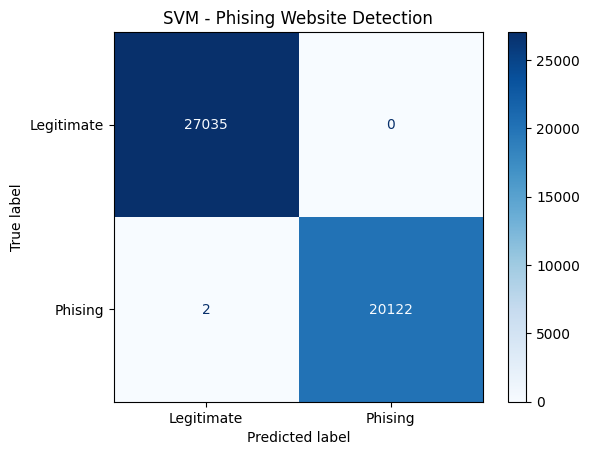

In [63]:
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate","Phising"]).plot(cmap="Blues",values_format="d")
plt.title("SVM - Phising Website Detection")
plt.show()

In [70]:
precision=precision_score(y_test,y_pred,zero_division=0)
recall=recall_score(y_test,y_pred,zero_division=0)
f1=f1_score(y_test,y_pred,zero_division=0)
roc_auc_score=roc_auc_score(y_test,y_score)

In [72]:
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
print(f"ROC AUC: {roc_auc_score:.4f}")
print("\nClassification_report")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0,1],
        target_names=["Phishing","Legitimate"],
        zero_division=0
    )
)

Precision: 1.0000
Recall: 0.9999
F1-score: 1.0000
ROC AUC: 1.0000

Classification_report
              precision    recall  f1-score   support

    Phishing       1.00      1.00      1.00     27035
  Legitimate       1.00      1.00      1.00     20124

    accuracy                           1.00     47159
   macro avg       1.00      1.00      1.00     47159
weighted avg       1.00      1.00      1.00     47159



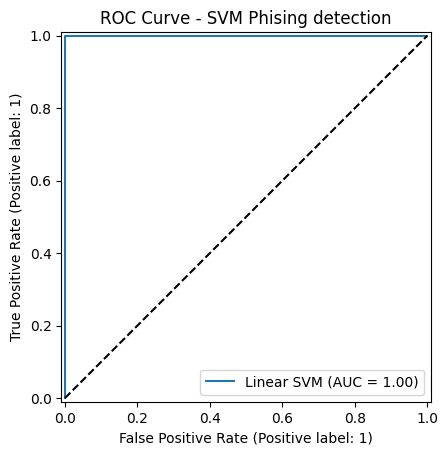

In [73]:
RocCurveDisplay.from_predictions(
    y_test,
    y_score,
    name="Linear SVM"
)
plt.plot([0,1],[0,1],"k--")
plt.title("ROC Curve - SVM Phising detection")
plt.show()